# Customer Segmentation with Clustering
**Goal:** segment a set of wholesale customers into groups using k-means, decide how many
groups with the **elbow method** and the **silhouette score**, and explain what each segment is.



## Your dataset

Use the **Wholesale Customers** dataset: annual spending (monetary units) by 440 clients of a
wholesale distributor across product categories.

- Download: [UCI Wholesale Customers](https://archive.ics.uci.edu/dataset/292/wholesale+customers) (also searchable as "Wholesale customers" on Kaggle).
- Columns: `Channel`, `Region` (these are labels, not spending), then the six spend columns `Fresh`, `Milk`, `Grocery`, `Frozen`, `Detergents_Paper`, `Delicassen`.
- Cluster on the **six spend columns**. `Channel` and `Region` are context only; do not cluster on them.

In [1]:
# Step 0: imports (given - just run this)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

ETSU_NAVY = "#00053E"
ETSU_GOLD = "#FFC72C"
print("Ready.")

Ready.


## Step 1: Load the data

Change the path to the real Wholesale file when you have it.

In [2]:
# GIVEN: load the data
df = pd.read_csv("wholesale_sample.csv")
spend_cols = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,1,1,4181,10024,26577,1979,9194,1151
1,2,3,3346,4848,14310,1155,2666,1768
2,2,3,3687,8096,10837,870,7701,1345
3,1,2,3008,6327,16926,1032,5303,1582
4,2,3,4704,13163,20537,1507,3073,1267


## Step 2: Explore

Look at the data before clustering: size, column types, and the ranges of the spend columns
(the ranges tell you whether scaling is needed).

In [6]:
# TODO: explore the data
# Hint: df.shape, df.info(), and df[spend_cols].describe()

print(df.shape)
print()
print(df.info())
print()
print(df[spend_cols].describe())


(150, 8)

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           150 non-null    int64
 1   Region            150 non-null    int64
 2   Fresh             150 non-null    int64
 3   Milk              150 non-null    int64
 4   Grocery           150 non-null    int64
 5   Frozen            150 non-null    int64
 6   Detergents_Paper  150 non-null    int64
 7   Delicassen        150 non-null    int64
dtypes: int64(8)
memory usage: 9.5 KB
None

              Fresh          Milk       Grocery       Frozen  \
count    150.000000    150.000000    150.000000   150.000000   
mean   10298.826667   5422.726667   7938.353333  3017.386667   
std     8398.147983   3820.906314   7053.621991  1977.922844   
min     2043.000000   1313.000000   1451.000000   760.000000   
25%     3923.250000   2524.250000   2877.750000  1461.500000   
50%     5748.500000

## Step 3: Select features and scale

k-means uses distance, and these spend columns are on very different scales, so scale them.

- Build X from the six spend columns.
- Scale with StandardScaler.

In [7]:
# TODO: build X from the spend columns and scale it
# Hint: X = df[spend_cols].values
# Hint: Xs = StandardScaler().fit_transform(X)

X = df[spend_cols].values
Xs = StandardScaler().fit_transform(X)


## Step 4: Choose the number of clusters (elbow + silhouette)

Try a range of k (say 2 to 10). For each k, fit k-means and record two things:

- `kmeans.inertia_` for the **elbow** plot (tightness; look for where the curve bends),
- `silhouette_score(Xs, labels)` for the **silhouette** plot (separation; higher is better).

Plot both, then pick a k and justify it in a sentence.

Text(0, 0.5, 'sils')

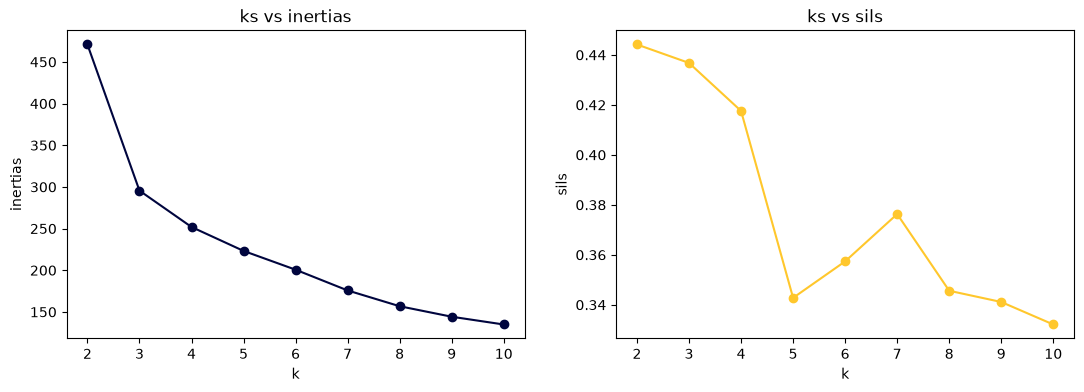

In [ ]:
# TODO: loop over k, collect inertia and silhouette, then plot both
# Hint:
# ks = range(2, 11)
# inertias, sils = [], []
# for k in ks:
#     km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xs)
#     inertias.append(km.inertia_)
#     sils.append(silhouette_score(Xs, km.labels_))
# then make two plots: ks vs inertias, and ks vs sils

ks = range(2, 11)
inertias, sils = [], []

for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xs)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(Xs, km.labels_))

fig, ax = plt.subplots(1, 2, figsize =(13, 4))

ax[0].plot(list(ks), inertias, "o-", color=ETSU_NAVY)
ax[0].set_title("ks vs inertias"); ax[0].set_xlabel("k"); ax[0].set_ylabel("inertias")

ax[1].plot(list(ks), sils, "o-", color=ETSU_GOLD)
ax[1].set_title("ks vs sils"); ax[1].set_xlabel("k"); ax[1].set_ylabel("sils")


**Your chosen k and why:**
<br>  I chose 4 clusters because the elbow plot showed that the inertia began flattening around 3–4 clusters, meaning additional clusters provided diminishing improvements. Although the silhouette score was highest at 2 clusters, I chose 4 because it provided more detailed customer segments with distinct purchasing patterns.

## Step 5: Fit k-means with your chosen k

In [18]:
# TODO: fit KMeans at your chosen k and attach the labels to df
# Hint: kmeans = KMeans(n_clusters=YOUR_K, random_state=42, n_init=10).fit(Xs)
# Hint: df["cluster"] = kmeans.labels_

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10).fit(Xs)
df["cluster"] = kmeans.labels_

## Step 6: Visualize the clusters with PCA

You have six features, so you cannot plot them directly. Reduce the scaled data to 2D with PCA
and color the points by cluster.

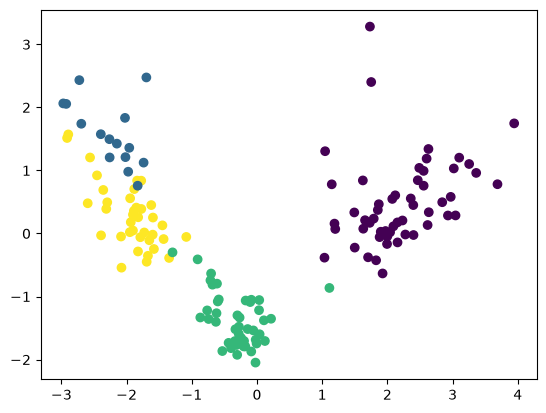

In [19]:
# TODO: project Xs to 2D with PCA and scatter it, colored by df["cluster"]
# Hint: pcs = PCA(n_components=2).fit_transform(Xs)
# Hint: plt.scatter(pcs[:,0], pcs[:,1], c=df["cluster"])

pcs = PCA(n_components=2).fit_transform(Xs)
plt.scatter(pcs[:,0], pcs[:,1], c=df["cluster"])


## Step 7: Profile and interpret the segments

Summarize each cluster by the average of each spend column (and how many customers are in it),
then describe each segment in plain words.

In [24]:
# TODO: build a profile table of per-cluster averages
# Hint: df.groupby("cluster")[spend_cols].mean().round(0)
# Hint: df["cluster"].value_counts() for the sizes

print(df.groupby("cluster")[spend_cols].mean().round(0))
print()
print(df["cluster"].value_counts().sort_index())


           Fresh    Milk  Grocery  Frozen  Detergents_Paper  Delicassen
cluster                                                                
0         4160.0  9696.0  15961.0  1548.0            6345.0      1668.0
1        20884.0  3051.0   3646.0  4885.0             840.0      3793.0
2         5578.0  2837.0   3075.0  2144.0            1415.0      1232.0
3        20581.0  3223.0   3753.0  5444.0             806.0      1897.0

cluster
0    54
1    15
2    44
3    37
Name: count, dtype: int64


## Step 8: Findings

1. **How many clusters did you choose, and why?** (what the elbow and silhouette showed) 
<br>  4 because there was the biggest drop at 2-3 and it started to flatten around 4-5

2. **Describe each segment** in plain language. What kind of customer is it (for example, a grocery-heavy retailer vs a fresh-and-frozen restaurant supplier)?
<br>  Cluster 0: People who spend a lot on groceries
<br>  Cluster 1: People who spend a lot on fresh products
<br>  Cluster 2: People that dont spend much
<br>  Cluster 3: People who spend a lot on fresh and some on frozen

3. **One action per segment:** what should the distributor do differently for each group?
<br>  Cluster 0: Prioritize grocery, milk, and detergent inventory. Offer bulk discounts and bundle household products with grocery purchases.
<br>  Cluster 1: Focus on fresh product quality, frequent deliveries, and premium delicatessen selections. Offer promotions on fresh and specialty foods.
<br>  Cluster 2: Offer smaller order quantities, affordable product bundles, and targeted discounts to encourage additional purchases.
<br>  Cluster 3: Maintain reliable fresh and frozen inventory. Offer combined fresh/frozen promotions and ensure proper storage and delivery.

4. **One limitation:** what would you want to check or try next (different k, more features, outliers)?
<br>  I would next experiment with different K values, particularly comparing 2 and 4 clusters, since the silhouette score was highest at 2 while the elbow method suggested around 4. I would also investigate potential outliers that could influence the cluster centers. Finally, I would consider adding features such as total spending or spending proportions to identify more specific customer purchasing patterns. These experiments could help determine whether the current four-cluster model is the best representation of the distributor's customers.


## Submission checklist

- This notebook, renamed `Lastnames_Clustering.ipynb`, all cells run with output showing